In [12]:
from langgraph.graph import StateGraph
from langgraph.constants import START, END
from langchain.chat_models import init_chat_model
from IPython.display import display, Image
import os

from typing import TypedDict, Literal, Annotated
from dotenv import load_dotenv
load_dotenv(override=True)
qwen_model = init_chat_model("openai:qwen3.7-plus", temperature=0, base_url=os.getenv("ROOT_URL"))



### Simple LLM Node

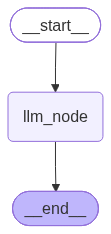

In [ ]:
class LLMState(TypedDict):
    user_message: str
    ai_message: str


def llm_node(state: LLMState): 
    user_message = state.get("user_message", "")
    ai_message = qwen_model.invoke(
       user_message,
    )
    return {"ai_message": ai_message.text}


builder = StateGraph(LLMState)
builder.add_node("llm_node", llm_node)  # 添加节点
builder.add_edge(START, "llm_node")  # 添加边
builder.add_edge("llm_node", END)  # 添加边
graph = builder.compile()  # 编译图

display(Image(graph.get_graph().draw_mermaid_png()))
# graph.invoke({"user_message": "Hello, what is your name?"})  # 调用图

### Improve1: MessageState

In [ ]:
from operator import add
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, BaseMessage

class LLMState(TypedDict):
    messages: Annotated[list[BaseMessage], add]


def llm_node(state: LLMState): 
    messages = state.get("messages", "")
    ai_message = qwen_model.invoke(
       messages,
    )
    return {"messages": [ai_message]}


builder = StateGraph(LLMState)
builder.add_node("llm_node", llm_node)  # 添加节点
builder.add_edge(START, "llm_node")  # 添加边
builder.add_edge("llm_node", END)  # 添加边
graph = builder.compile()  # 编译图

# display(Image(graph.get_graph().draw_mermaid_png()))
result = graph.invoke({"messages": HumanMessage(content="Hello, what is your name?")})  # 调用图
print(result)

{'messages': [AIMessage(content='Hello! How can I help you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 171, 'prompt_tokens': 10, 'total_tokens': 181, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 159, 'rejected_prediction_tokens': None, 'text_tokens': 171}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'text_tokens': 10}}, 'model_provider': 'openai', 'model_name': 'qwen3.7-plus', 'system_fingerprint': None, 'id': 'chatcmpl-bef42d45-e23e-980c-8815-d7ac6cab1b2b', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1ba3b-9898-7033-a7ff-c07c5f3de78e-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 10, 'output_tokens': 171, 'total_tokens': 181, 'input_token_details': {'cache_read': 0}, 'output_token_details': {'reasoning': 159}})]}

In [14]:
from langgraph.graph import MessagesState

def llm_node(state: MessagesState): 
    messages = state.get("messages", "")
    ai_message = qwen_model.invoke(
       messages,
    )
    return {"messages": [ai_message]}


builder = StateGraph(MessagesState)
builder.add_node("llm_node", llm_node)  # 添加节点
builder.add_edge(START, "llm_node")  # 添加边
builder.add_edge("llm_node", END)  # 添加边
graph = builder.compile()  # 编译图

# display(Image(graph.get_graph().draw_mermaid_png()))
result = graph.invoke({"messages": HumanMessage(content="Hello, what is your name?")})  # 调用图
print(result)

{'messages': [HumanMessage(content='Hello, what is your name?', additional_kwargs={}, response_metadata={}, id='1d1055ec-5a76-4d6e-b6f7-b55af59b97cf'), AIMessage(content="Hello! I am Qwen, a large language model developed by Alibaba Group's Tongyi Lab. How can I help you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 140, 'prompt_tokens': 17, 'total_tokens': 157, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 110, 'rejected_prediction_tokens': None, 'text_tokens': 140}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'text_tokens': 17}}, 'model_provider': 'openai', 'model_name': 'qwen3.7-plus', 'system_fingerprint': None, 'id': 'chatcmpl-c2e57a82-ba7a-9db0-81bf-b424a2cd9bee', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1ba40-30f3-79e2-a4dc-7281c0c8ca11-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={

### Improve2: Message Store (checkpointer)

In [16]:
from langgraph.graph import MessagesState
from langgraph.checkpoint.memory import InMemorySaver

def llm_node(state: MessagesState): 
    messages = state.get("messages", "")
    ai_message = qwen_model.invoke(
       messages,
    )
    return {"messages": [ai_message]}


builder = StateGraph(MessagesState)
builder.add_node("llm_node", llm_node)  # 添加节点
builder.add_edge(START, "llm_node")  # 添加边
builder.add_edge("llm_node", END)  # 添加边
graph = builder.compile(checkpointer=InMemorySaver())  # 编译图

# display(Image(graph.get_graph().draw_mermaid_png()))
result = graph.invoke({
    "messages": HumanMessage(content="My name is Tommy, what is your name?"),},
    config = {"thread_id": "graph_checkpoint_1"}
    )  # 调用图
print(result)

{'messages': [HumanMessage(content='My name is Tommy, what is your name?', additional_kwargs={}, response_metadata={}, id='8d870c77-2883-46f2-bb7b-6a64d5cd4305'), AIMessage(content="Hi Tommy! My name is Qwen. It's nice to meet you! How can I help you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 374, 'prompt_tokens': 20, 'total_tokens': 394, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 348, 'rejected_prediction_tokens': None, 'text_tokens': 374}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'text_tokens': 20}}, 'model_provider': 'openai', 'model_name': 'qwen3.7-plus', 'system_fingerprint': None, 'id': 'chatcmpl-ccb51c58-c010-90ba-ad84-d7e0c3580c19', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1ba46-88c0-7ed1-b43e-df59f7b5592d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 20, '

In [17]:
result = graph.invoke({
    "messages": HumanMessage(content="Remind me what is my name?"),},
    config = {"thread_id": "graph_checkpoint_1"}
    )  # 调用图
print(result)

{'messages': [HumanMessage(content='My name is Tommy, what is your name?', additional_kwargs={}, response_metadata={}, id='8d870c77-2883-46f2-bb7b-6a64d5cd4305'), AIMessage(content="Hi Tommy! My name is Qwen. It's nice to meet you! How can I help you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 374, 'prompt_tokens': 20, 'total_tokens': 394, 'completion_tokens_details': {'accepted_prediction_tokens': None, 'audio_tokens': None, 'reasoning_tokens': 348, 'rejected_prediction_tokens': None, 'text_tokens': 374}, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0, 'text_tokens': 20}}, 'model_provider': 'openai', 'model_name': 'qwen3.7-plus', 'system_fingerprint': None, 'id': 'chatcmpl-ccb51c58-c010-90ba-ad84-d7e0c3580c19', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1ba46-88c0-7ed1-b43e-df59f7b5592d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 20, '

### Improve3: Tool Calls

In [19]:
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import HumanMessage
from langgraph.constants import START, END
from langgraph.graph import StateGraph, MessagesState
from langgraph.prebuilt import ToolNode, tools_condition


# ====== Step 1: 准备工具 ======
# 工具
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")

@tool
def get_time(city: str) -> str:
    """获取城市时间"""
    time_data = {
        "北京": "北京时间 14:00",
        "上海": "北京时间 14:00",
        "杭州": "北京时间 14:00",
    }
    return time_data.get(city, f"未找到{city}的时间信息")

# 组成工具数组
tools = [get_weather, get_time]

# ====== Step 2: 准备模型，绑定工具 ======

# 绑定工具到模型，与create_agent类似，将来LangChain会自动帮我们拼接tool信息发给模型
model_with_tools = qwen_model.bind_tools(tools)


# ====== Step 3: 定义Node ======
def llm_node(state: MessagesState):
    """LLM节点：调用模型，可以选择调用工具"""
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}

# ====== Step 4: 构建图 ======
builder = StateGraph(MessagesState)
builder.add_node("llm", llm_node)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "llm")
builder.add_conditional_edges("llm", tools_condition)
builder.add_edge("tools", "llm")  # 工具执行后回到LLM，形成循环
agent_graph = builder.compile()

# ====== Step 5: 调用 ======
result = agent_graph.invoke({
    "messages": [HumanMessage(content="北京和杭州今天天气怎么样？")]
})
for m in result['messages']:
    m.pretty_print()

================================ Human Message =================================

北京和杭州今天天气怎么样？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_c4047c8538df4462887cf4b7)
 Call ID: call_c4047c8538df4462887cf4b7
  Args:
    city: 北京
  get_weather (call_0bf5f507ae6d407aa2495098)
 Call ID: call_0bf5f507ae6d407aa2495098
  Args:
    city: 杭州
================================= Tool Message =================================
Name: get_weather

晴天 25度
================================= Tool Message =================================
Name: get_weather

小雨 22度
================================== Ai Message ==================================

今天两个城市的天气情况如下：

- **北京**：晴天，气温 25°C ☀️
- **杭州**：小雨，气温 22°C 🌧️

北京今天天气不错，适合外出；杭州有小雨，出门记得带伞哦！


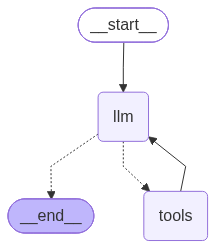

In [21]:
display(Image(agent_graph.get_graph().draw_mermaid_png()))
